# 7. EP search for a highly accelerated pulsar

A 36-minute observation of a pulsar with an acceleration of 1500 m/s²
and a folded S/N of only 8.5. The extreme pruning (EP) search (notebook
6) builds the phase model one segment at a time and keeps only the
nodes above the stage thresholds.

The phase model of each node is a polynomial in time, here in the
**Taylor** basis (frequency, acceleration, ...). loki can also use
Chebyshev coefficients over the current time span
(`poly_basis="chebyshev"`), which lays out the parameter grid
differently.

Runtime: about 1.5 minutes; memory: about 7.5 GB (4 threads).

In [1]:
%matplotlib inline
import shutil
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt

from loki import libloki
from loki.libloki.configs import PulsarSearchConfig
from loki.libloki.plans import FFAPlanBase
from loki.libloki.prune import EPMultiPassFourier
from pyloki.config import ParamLimits
from pyloki.periodogram import PruningStatsPlotter, ScatteredPeriodogram
from pyloki.simulation.pulse import PulseSignalConfig

libloki.set_log_level("warning")  # hide loki's per-run info messages
SEED = 1
NTHREADS = 4  # CPU threads; raise it on a machine of your own
OUTDIR = Path("_output/07_ep_acceleration")
shutil.rmtree(OUTDIR, ignore_errors=True)  # EP refuses to overwrite earlier runs

## Simulated data

A 7 ms pulsar, acceleration 1500 m/s², 10 % duty cycle, folded S/N 8.5,
in 2^25 samples of 64 µs. Over the observation the apparent spin
frequency changes by about 1 Hz. The fold at the true parameters:

T_obs = 2147.5 s, true frequency = 142.857143 Hz


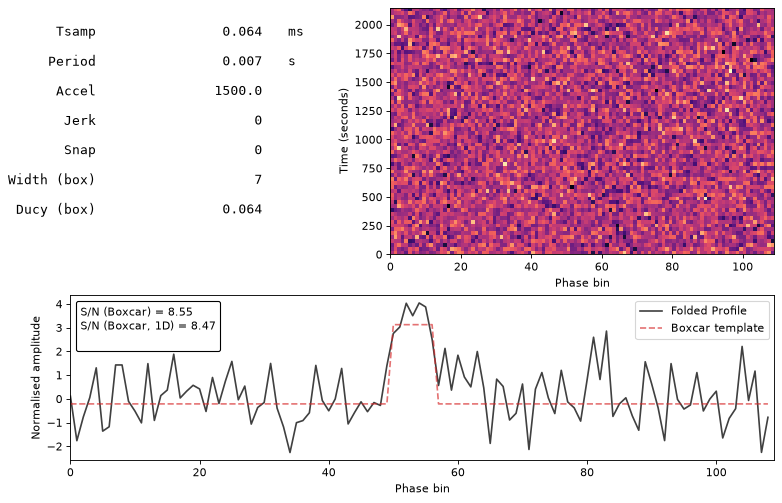

In [2]:
accel = 1500.0
mod_kwargs = {"acc": accel}
cfg = PulseSignalConfig(
    period=0.007,
    dt=64e-6,
    nsamps=2**25,
    snr=8.5,
    ducy=0.1,
    mod_kwargs=mod_kwargs,
    seed=SEED,
)
tim_data = cfg.generate(shape="gaussian")
print(f"T_obs = {cfg.tobs:.1f} s, true frequency = {cfg.freq:.6f} Hz")
tim_data.plot_fold(cfg.freq, cfg.fold_bins, mod_kwargs=mod_kwargs, dpi=80)
plt.show()

## Search configuration and thresholds

140–150 Hz, ±2500 m/s², a quadratic phase model (`prune_poly_order=2`)
and 128 segments (`bseg_ffa`). The threshold schedule is designed as in
notebook 6, for loki's default `target_snr` (8.5 for two parameters),
the injected S/N.

In [3]:
limits = ParamLimits.from_upper((140.0, 150.0), [accel], (-2500.0, 2500.0), cfg.tobs)
search_cfg = PulsarSearchConfig(
    nsamps=cfg.nsamps,
    tsamp=cfg.dt,
    nbins=64,
    eta=1,
    param_limits=limits.limits,
    bseg_brute=cfg.nsamps // 16384,
    bseg_ffa=cfg.nsamps // 128,
    prune_poly_order=2,
    nthreads=NTHREADS,
    ducy_max=0.5,
    wtsp=1.2,
    use_fourier=True,
)
plan = FFAPlanBase(search_cfg)
branching_pattern = np.asarray(plan.get_branching_pattern(), dtype=np.float32)
n_trees = plan.ncoords[-1]

target_snr, ref_ducy = search_cfg.target_snr, 0.1
dts = libloki.thresholds.DynamicThresholdScheme(
    branching_pattern,
    ref_ducy,
    search_cfg.nbins,
    snr_final=target_snr,
    ducy_max=search_cfg.ducy_max,
    wtsp=search_cfg.wtsp,
    mode="improved",
    beam_width=2.0,
    nthreads=NTHREADS,
    seed=SEED,
)
dts.run(thres_neigh=10, show_progress=False)
thresholds = np.asarray(dts.get_best_path_thresholds(min_pd=0.1), dtype=np.float32)
expected = libloki.thresholds.evaluate_scheme(
    thresholds,
    branching_pattern,
    ref_ducy,
    search_cfg.nbins,
    ntrials=2**14,
    snr_final=target_snr,
    ducy_max=search_cfg.ducy_max,
    wtsp=search_cfg.wtsp,
    seed=SEED + 1,  # fresh trials, not the threshold search's
)
print(
    f"{len(branching_pattern)} stages, {n_trees} trees; "
    f"P_d per run = {expected['success_h1_cumul'][-1]:.3f} (on fresh trials)",
)

127 stages, 20289 trees; P_d per run = 0.096 (on fresh trials)


The branching pattern (mean number of children per node at each stage)
and the number of leaves the schedule expects to survive in all trees
together, against the `max_sugg` cap of a run.

[4.   7.45 1.31 1.   2.36 3.81 1.   2.36 1.   1.27 1.   1.   1.   1.   2.36
 1.   1.   3.81 1.   1.   1.   1.   1.   1.   1.   2.36 1.   1.   1.   1.
 1.27 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.67
 1.42 1.   1.   1.   1.   1.   1.   1.   3.81 1.   1.   1.   1.   1.   1.
 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.
 1.   1.   1.3  1.42 1.28 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.
 1.   1.   1.12 1.14 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.
 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.
 1.   1.   1.   1.   1.   1.   1.  ]


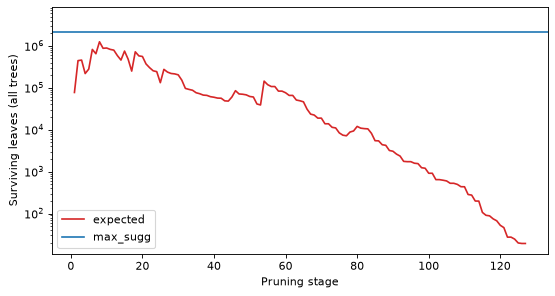

In [4]:
max_sugg = 2**21
print(np.array2string(branching_pattern, precision=2, max_line_width=78))

stages = np.arange(1, len(branching_pattern) + 1)
fig, ax = plt.subplots(figsize=(8, 4), dpi=80)
ax.semilogy(stages, expected["complexity"] * n_trees, c="tab:red", label="expected")
ax.axhline(max_sugg, c="tab:blue", label="max_sugg")
ax.set_xlabel("Pruning stage")
ax.set_ylabel("Surviving leaves (all trees)")
ax.set_ylim(None, 4 * max_sugg)
ax.legend()
plt.show()

## Run the search

`n_runs=32` independent runs, each growing its trees from a different
reference segment. Each run detects a pulsar of the design S/N with
probability `P_d ≈ 0.1`, so 32 runs find it with probability about
`1 - 0.9^32 ≈ 0.97`. `max_sugg` caps the surviving leaves of a run.

In [5]:
ep = EPMultiPassFourier(
    search_cfg,
    thresholds,
    n_runs=32,
    max_sugg=max_sugg,
    batch_size=1024,
    poly_basis="taylor",
    show_progress=False,
)
ep.execute(tim_data.ts_e, tim_data.ts_v, outdir=str(OUTDIR), file_prefix="accel")
result_file = next(OUTDIR.glob("accel_*_results.h5"))

## Candidates

The best final leaves over all runs. `S/N (EP)` is the score the pruning
used; `S/N` is the boxcar S/N of the final fold. Run IDs are
`<reference segment>_<run>`; one run usually contributes several
neighbouring leaves.

In [6]:
true_values = {"accel": accel, "freq": cfg.freq}
print(f"True parameters: accel = {accel:.3f}, freq = {cfg.freq:.10f}")
pgram = ScatteredPeriodogram.load(str(result_file))
print(pgram.get_summary_cands(10, score_type="score", run_id=None))

True parameters: accel = 1500.000, freq = 142.8571428571
Top candidates:
dparams: daccel: 0.1897242209, dfreq: 2.299489501e-05
Run: 032_09, S/N (EP): 8.46, S/N: 8.03, accel: 1500.01, freq: 142.857147
Run: 045_12, S/N (EP): 8.03, S/N: 8.03, accel: 1500.10, freq: 142.857145
Run: 045_12, S/N (EP): 7.96, S/N: 7.96, accel: 1500.10, freq: 142.857122
Run: 049_13, S/N (EP): 7.62, S/N: 7.96, accel: 1499.98, freq: 142.857116
Run: 032_09, S/N (EP): 8.62, S/N: 7.95, accel: 1500.01, freq: 142.857124
Run: 032_09, S/N (EP): 7.79, S/N: 7.86, accel: 1500.20, freq: 142.857133
Run: 045_12, S/N (EP): 7.49, S/N: 7.71, accel: 1499.91, freq: 142.857105
Run: 032_09, S/N (EP): 7.47, S/N: 7.63, accel: 1500.20, freq: 142.857156
Run: 032_09, S/N (EP): 7.39, S/N: 7.60, accel: 1500.01, freq: 142.857101
Run: 049_13, S/N (EP): 7.47, S/N: 7.59, accel: 1499.98, freq: 142.857093


Final S/N of every leaf in every run, per run and as a histogram over
all runs. Most runs end with noise leaves below the design S/N; the
runs that kept the pulsar stand out.

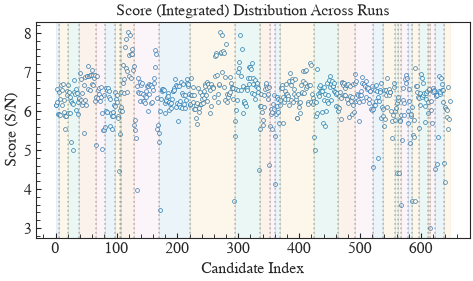

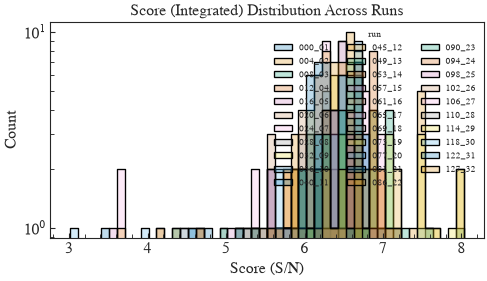

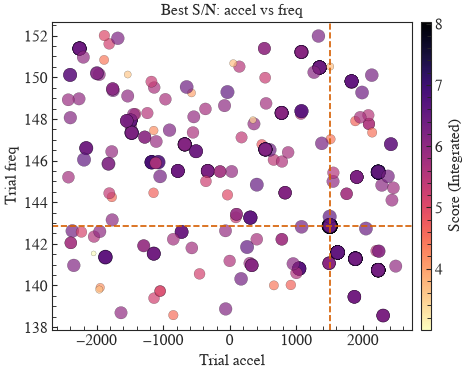

In [7]:
pgram.plot_scores(kind="scatter", run_id=None, dpi=80)
plt.show()
pgram.plot_scores(kind="hist", run_id=None, dpi=80)
plt.show()
pgram.plot_correlation(
    "accel",
    "freq",
    true_values=true_values,
    run_id=None,
    figsize=(7, 5),
    dpi=80,
)
plt.show()

## Tree size: expected vs measured

Surviving leaves per stage in each run (from the run statistics), with
the expectation of the threshold design (red) and the `max_sugg` cap
(blue). Noise leaves dominate, so the measured counts follow the design.

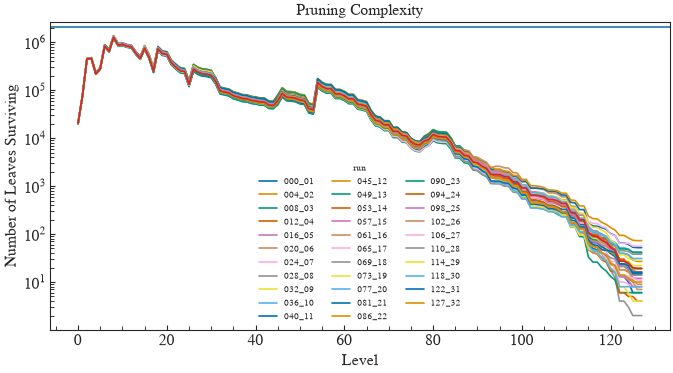

In [8]:
pstats = PruningStatsPlotter.load(str(result_file))
fig = pstats.plot_level_stats(run_id=None, dpi=80)
stages = np.arange(0, len(branching_pattern) + 1)
ax = fig.axes[0]
ax.plot(
    stages,
    np.concatenate(([1], expected["complexity"])) * n_trees,
    c="tab:red",
    label="expected",
)
ax.axhline(max_sugg, c="tab:blue", label="max_sugg")
plt.show()

## Recovery

The best leaf at the pulsar (within 1 m/s² and 10^-4 Hz of the truth),
and the number of runs that kept one; the design expects about
`P_d × 32 ≈ 3`.

In [9]:
leaves = pgram.data
near = (abs(leaves["accel"] - accel) < 1.0) & (abs(leaves["freq"] - cfg.freq) < 1e-4)
best = leaves[near].nlargest(1, "score").iloc[0]
print(
    f"best S/N {best['score']:.2f} at accel {best['accel']:.2f}, "
    f"freq error {best['freq'] - cfg.freq:.2e} Hz",
)
print(f"runs that kept the pulsar: {leaves.loc[near, 'run_id'].nunique()} of 32")

best S/N 8.03 at accel 1500.01, freq error 3.86e-06 Hz
runs that kept the pulsar: 5 of 32
